<center>
<h1><b> TP3: Prompt Engineering </b>
<h1><b>Classification tasks : Sentiment Analysis </b>
</center>

# Objectives

- Present LLMs as an effective tool to tackle classification problems.
- Illustrate prompt engineering for sentiment analysis.
- Build and evaluate LLMs on broader classification tasks.


# Preparer l'environement

1. Prendre VS Code, je vais créer un un nouveau dossier que je vais appeler **SMA_TokPr** et ouvrir le terminal.
2. **UV** install: utiliser la la commande, pour MacOS: ```curl -LsSf https://astral.sh/uv/install.sh | sh```  sous Windows utiliser la commande dans le powerShell: `powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"`. Après instalation de UV quittez et relancez VScode.
3. dans le terminal de VsCode utiliser la commande ` uv init ` pour initialiser le projet. Donc ça nous permet de générer la structure des projets notamment avec le fichier **.toml** .
4. créer un environnement virtuel. Avec la commande: ` uv venv ` .
3. autoriser PowerSell à exécuter les scripts avec cette commande dans le terminal: ` Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process ` . puis aller au dosssier **Scripts** et activer les scripts avec la commande:  ` .\.venv\Scripts\activate `.
5.  cree un notebook **prompttoken.ipynb** pour le test puis choisir un noyaux(le kernel) et tester avec `print("Bonjour")` .
  

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
from dotenv import load_dotenv

load_dotenv(override=True)

True

In [2]:
try:
    import session_info
    session_info.show()
except ImportError:
    print("session_info non installé (optionnel) : uv add session-info")

## Step 1 : Define Objectives and Metrics

Chaque avis reçoit l'étiquette **positive** ou **negative**. Métriques :
- **Accuracy** : prédictions correctes / total.
- **Micro-F1** : on agrège TP, FP, FN sur toutes les classes (adapté quand les classes sont équilibrées).

Exemple du cours : TP = 50, FP = 10, FN = 5.

In [3]:
TP, FP, FN = 50, 10, 5
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
print(f"Micro-précision = {precision:.3f}")
print(f"Micro-rappel    = {recall:.3f}")
print(f"Micro-F1        = {f1:.3f}")   # 0.870

Micro-précision = 0.833
Micro-rappel    = 0.909
Micro-F1        = 0.870


## Step 2 : Assemble Data

Dataset : avis IMDB (fichier CSV local, colonnes `review` et `sentiment`).
Le CSV est cherché automatiquement dans le dossier du notebook et ses sous-dossiers.

In [4]:
CSV_NAME = "IMDB Dataset.csv"  

# Recherche automatique du CSV (dossier courant, parents, sous-dossiers)
candidates = []
for base in [Path.cwd(), *Path.cwd().parents[:2]]:
    candidates += list(base.rglob(CSV_NAME))
    if candidates:
        break
if not candidates:
    csvs = [str(p) for p in Path.cwd().rglob("*.csv") if ".venv" not in p.parts]
    raise FileNotFoundError(
        f"'{CSV_NAME}' introuvable depuis {Path.cwd()}.\n"
        f"Copie le CSV dans ce dossier, ou mets son chemin complet dans CSV_PATH.\n"
        f"CSV trouvés : {csvs}"
    )
CSV_PATH = candidates[0]
print("CSV utilisé :", CSV_PATH)

train_df = pd.read_csv(CSV_PATH)
print(train_df.shape, train_df.columns.tolist())
train_df.head()

CSV utilisé : d:\M2\P1\SDI\tp3\data\IMDB Dataset.csv
(50000, 2) ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


In [6]:
# Normalisation des colonnes -> 'text' et 'sentiment' (positive / negative)
train_df = train_df.rename(columns={"review": "text"})
if "label" in train_df.columns and "sentiment" not in train_df.columns:
    train_df["sentiment"] = np.where(train_df.label == 1, "positive", "negative")
train_df["sentiment"] = train_df["sentiment"].astype(str).str.strip().str.lower()
train_df = train_df[["text", "sentiment"]].dropna().reset_index(drop=True)
train_df["text"] = train_df.text.str.replace("<br />", " ", regex=False)

# Limite de taille des avis : économise les tokens (Groq gratuit = limite de tokens/minute,
# Ollama local = prompts plus rapides). Mettre MAX_CHARS = None pour garder tous les avis.
MAX_CHARS = 800
if MAX_CHARS:
    train_df = train_df[train_df.text.str.len() <= MAX_CHARS]
    # on rééquilibre positif / négatif (le dataset doit rester équilibré, comme dans le cours)
    n_min = train_df.sentiment.value_counts().min()
    train_df = train_df.groupby("sentiment").sample(n_min, random_state=42).reset_index(drop=True)

train_df.sentiment.value_counts()

sentiment
negative    9221
positive    9221
Name: count, dtype: int64

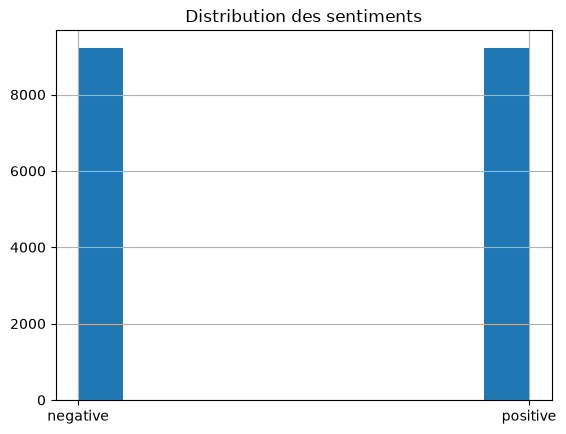

In [7]:
train_df.sentiment.hist()
plt.title("Distribution des sentiments")
plt.show()

In [8]:
train_df.sample(6)

,text,sentiment
280,"Hooper is Not Funny, Not Fasted paced, Not rom...",negative
10442,"I really enjoyed this movie. During the movie,...",positive
3786,Maybe it was the fact that I saw Spider-man th...,negative
11206,i think it is a nice movie; i think it is a ve...,positive
13821,"From the golden period of British films, this ...",positive
17256,i liked this movie a lot.I rented this expecti...,positive


On divise les données en deux segments : un réservoir d'**exemples few-shot** et un réservoir d'**exemples de référence (gold)**, puis on les sauvegarde en JSON.

In [9]:
examples_df, gold_examples_df = train_test_split(
    train_df, test_size=0.2, random_state=42
)
print(examples_df.shape, gold_examples_df.shape)

(14753, 2) (3689, 2)


In [10]:
examples_df.to_json("examples.json", orient="records")
gold_examples_df.to_json("gold_examples.json", orient="records")

In [11]:
columns = ["text", "sentiment"]
gold_examples = (
    gold_examples_df.loc[:, columns]
    .sample(20, random_state=42)
    .to_json(orient="records")
)
json.loads(gold_examples)[0]

{'text': 'I saw this movie for 2 reasons--I like Gerard Butler and Christopher Plummer. Unfortunately, these poor men were forced to carry a pretty dumb movie. I liked the idea that Dracula is actually a reincarnation of Judas Iscariot, because it does explain his disdain for all things Christian, but there was so much camp that this idea was not realized as much as it could have been. I see this movie more as a way for the talented Gerard Butler to pay his dues before being truly recognized and a way for the legendary Christopher Plummer to remind the public (me and the 5 other people who saw this film) that he still exists. I actually enjoyed the special features on the DVD more than the movie itself.',
 'sentiment': 'negative'}

## Step 3 : Élaborer le prompt

### Prompt 1 : Zero-shot

In [12]:
zero_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""

user_message_template = """```{movie_review}```"""

zero_shot_prompt = [{"role": "system", "content": zero_shot_system_message}]

### Prompt 2 : Few-shot

Le message système ne change pas ; on l'enrichit avec des exemples few-shot (4 positifs + 4 négatifs = 8 exemples).

In [13]:
few_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""

positive_reviews = (examples_df.sentiment == "positive")
negative_reviews = (examples_df.sentiment == "negative")
print(positive_reviews.shape, negative_reviews.shape)

columns = ["text", "sentiment"]
positive_examples = examples_df.loc[positive_reviews, columns].sample(4)
negative_examples = examples_df.loc[negative_reviews, columns].sample(4)

(14753,) (14753,)


In [14]:
positive_examples

,text,sentiment
10975,This movie has made me a rugby -- and Coach La...,positive
14299,Doctor Who is amazing. It is everyones 'cup of...,positive
10179,Years ago I did follow a soap on TV. So I was ...,positive
11441,This movie is just so good! Despite Carmen Ele...,positive


In [15]:
negative_examples

,text,sentiment
7365,One of the worst movies I've ever seen. When I...,negative
7624,The first 4 episodes of season 6 are just to t...,negative
7152,Ulises is a literature teacher that arrives to...,negative
652,"... in search of the cheesiest ""so bad it's go...",negative


Un simple tirage aléatoire ne suffit pas : les exemples sont sujets au **biais de l'étiquette majoritaire** et au **biais de récence** (exemples situés vers la fin du prompt). On génère donc des exemples **équilibrés** et dans un **ordre aléatoire**.

In [16]:
def create_examples(dataset, n=4):
    positive_reviews = (dataset.sentiment == "positive")
    negative_reviews = (dataset.sentiment == "negative")
    columns_to_select = ["text", "sentiment"]
    positive_examples = dataset.loc[positive_reviews, columns_to_select].sample(n)
    negative_examples = dataset.loc[negative_reviews, columns_to_select].sample(n)
    examples = pd.concat([positive_examples, negative_examples])
    # sampling without replacement is equivalent to random shuffling
    randomized_examples = examples.sample(2 * n, replace=False)
    return randomized_examples.to_json(orient="records")


examples = create_examples(examples_df, 2)
json.loads(examples)

[{'text': '"Antwone Fisher" tells of a young black U.S. Navy enlisted man and product of childhood abuse and neglect (Luke) whose hostility toward others gets him a stint with the base shrink (Washington) leading to introspection, self appraisal, and a return to his roots. Pat, sanitized, and sentimental, "Antwone Fisher" is a solid feel-good flick about the reconciliation of past regrets and closure. Good old Hollywood style entertainment family values entertainment with just a hint of corn. (B)',
  'sentiment': 'positive'},
 {'text': "This film tells the story of a romance between Albert Einstien niece and a gas station attendant. In order to get the two together, Einstien agrees to help Ed(Hudsucker Proxy's Tim Robbins) learn to act more intelligent. This impresses Catherine (Meg Ryan). Unfortunately Einstien goes too far and Ed is considered to be a genius. Hilarity ensues. Not to be missed. Filmed in Mercer county New Jersey at Princeton University, Lawrenceville Prep School (doub

In [17]:
def create_prompt(system_message, examples, user_message_template):
    few_shot_prompt = [{"role": "system", "content": system_message}]
    for example in json.loads(examples):
        example_review = example["text"]
        example_sentiment = example["sentiment"]
        few_shot_prompt.append(
            {"role": "user",
             "content": user_message_template.format(movie_review=example_review)}
        )
        few_shot_prompt.append(
            {"role": "assistant", "content": f"{example_sentiment}"}
        )
    return few_shot_prompt


few_shot_prompt = create_prompt(few_shot_system_message, examples, user_message_template)
few_shot_prompt

[{'role': 'system',
  'content': "\nClassify the sentiment of movie reviews presented in the input as 'positive' or 'negative'\nMovie reviews will be delimited by triple backticks in the input.\nAnswer only 'positive' or 'negative'\nDo not explain your answer.\n"},
 {'role': 'user',
  'content': '```"Antwone Fisher" tells of a young black U.S. Navy enlisted man and product of childhood abuse and neglect (Luke) whose hostility toward others gets him a stint with the base shrink (Washington) leading to introspection, self appraisal, and a return to his roots. Pat, sanitized, and sentimental, "Antwone Fisher" is a solid feel-good flick about the reconciliation of past regrets and closure. Good old Hollywood style entertainment family values entertainment with just a hint of corn. (B)```'},
 {'role': 'assistant', 'content': 'positive'},
 {'role': 'user',
  'content': "```This film tells the story of a romance between Albert Einstien niece and a gas station attendant. In order to get the tw

### Prompt 3 : Chain-of-Thought (CoT)

Même exemples que le few-shot ; seul le message système change (instructions étape par étape).

In [18]:
cot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks ``` in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.

Instructions:
1. Carefully read the text of the review and think through the options for sentiment provided
2. Consider the overall sentiment of the review and estimate the probability of the review being positive

To reiterate, your answer should strictly only contain the label: positive or negative
"""

cot_few_shot_prompt = create_prompt(cot_system_message, examples, user_message_template)

## Step 4 : Evaluate Prompts

Choix du LLM : `"groq"` (API Groq, clé `GROQ_API_KEY` dans `.env`), `"ollama"` (modèle local) ou `"grok"` (xAI).

In [19]:
import os, re, time
from langchain_ollama import ChatOllama
from langchain_openai import ChatOpenAI   # client compatible OpenAI -> utilisé pour Groq / xAI

PROVIDER = "ollama"                     # "groq", "ollama" ou "grok"
GROQ_MODEL = "openai/gpt-oss-20b"
OLLAMA_MODEL = "llama3.2:3b"            # local : ollama pull llama3.2:3b
GROK_MODEL = "grok-4"
SLEEP_BETWEEN_CALLS = 2.5 if PROVIDER == "groq" else 0   # Groq gratuit : ~30 requêtes/minute


def get_llm(provider):
    if provider == "groq":
        return ChatOpenAI(model=GROQ_MODEL, base_url="https://api.groq.com/openai/v1",
                          api_key=os.getenv("GROQ_API_KEY"), temperature=0,
                          reasoning_effort="low")
    if provider == "grok":
        return ChatOpenAI(model=GROK_MODEL, base_url="https://api.x.ai/v1",
                          api_key=os.getenv("XAI_API_KEY"), temperature=0)
    return ChatOllama(model=OLLAMA_MODEL, temperature=0)


def clean_response(text):
    """Enlève le bloc de réflexion (<think> ... </think>) que certains modèles (Qwen...) ajoutent."""
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S | re.I)
    if "</think>" in text:
        text = text.split("</think>")[-1]
    return text.strip()


def invoke_with_retry(model, messages, max_retries=8):
    """Relance automatiquement en cas de limite de débit (429)."""
    for attempt in range(max_retries):
        try:
            return model.invoke(messages)
        except Exception as e:
            if "429" in str(e) or "rate limit" in str(e).lower():
                wait = min(10 * (attempt + 1), 60)
                print(f"Limite de débit atteinte, nouvelle tentative dans {wait}s...")
                time.sleep(wait)
            else:
                raise
    raise RuntimeError("Trop de tentatives (limite de débit).")


llm = get_llm(PROVIDER)

try:
    print(repr(clean_response(llm.invoke("Say 'ok'").content)))
except Exception as e:
    msg = str(e)
    if "401" in msg:
        print("401 : clé API invalide/absente (GROQ_API_KEY dans .env) ou Ollama non connecté.")
    elif "402" in msg:
        print("402 : modèle payant. Utilise PROVIDER = 'groq' ou un modèle Ollama local.")
    elif "404" in msg or "not found" in msg.lower() or "model_not_found" in msg:
        print("Modèle introuvable : change GROQ_MODEL / OLLAMA_MODEL (ollama pull ...).")
    raise

'Ok'


In [20]:
def evaluate_prompt(prompt, gold_examples, user_message_template, model, return_preds=False):
    model_predictions, ground_truths = [], []
    for example in json.loads(gold_examples):
        gold_input = example["text"]
        user_input = [
            {"role": "user",
             "content": user_message_template.format(movie_review=gold_input)}
        ]
        try:
            response = invoke_with_retry(model, prompt + user_input)
            if hasattr(response, "content"):
                response_content = response.content
            else:
                response_content = response
            response_content = clean_response(response_content)
            if "negative" in response_content.strip().lower():
                prediction = "negative"
            elif "positive" in response_content.strip().lower():
                prediction = "positive"
            else:
                prediction = "unknown"
            model_predictions.append(prediction)
            ground_truths.append(example["sentiment"])
            # print(prediction, example["sentiment"])
            time.sleep(SLEEP_BETWEEN_CALLS)
        except Exception as e:
            print(e)
            continue
    micro_f1_score = f1_score(ground_truths, model_predictions, average="micro")
    if return_preds:
        return micro_f1_score, ground_truths, model_predictions
    return micro_f1_score

In [21]:
zero_f1, yt_zero, yp_zero = evaluate_prompt(zero_shot_prompt, gold_examples, user_message_template, llm, True)
few_f1, yt_few, yp_few = evaluate_prompt(few_shot_prompt, gold_examples, user_message_template, llm, True)
cot_f1, yt_cot, yp_cot = evaluate_prompt(cot_few_shot_prompt, gold_examples, user_message_template, llm, True)

print(f"Zero-shot micro-F1 : {zero_f1:.3f}")
print(f"Few-shot  micro-F1 : {few_f1:.3f}")
print(f"CoT       micro-F1 : {cot_f1:.3f}")

Zero-shot micro-F1 : 0.900
Few-shot  micro-F1 : 0.950
CoT       micro-F1 : 0.950


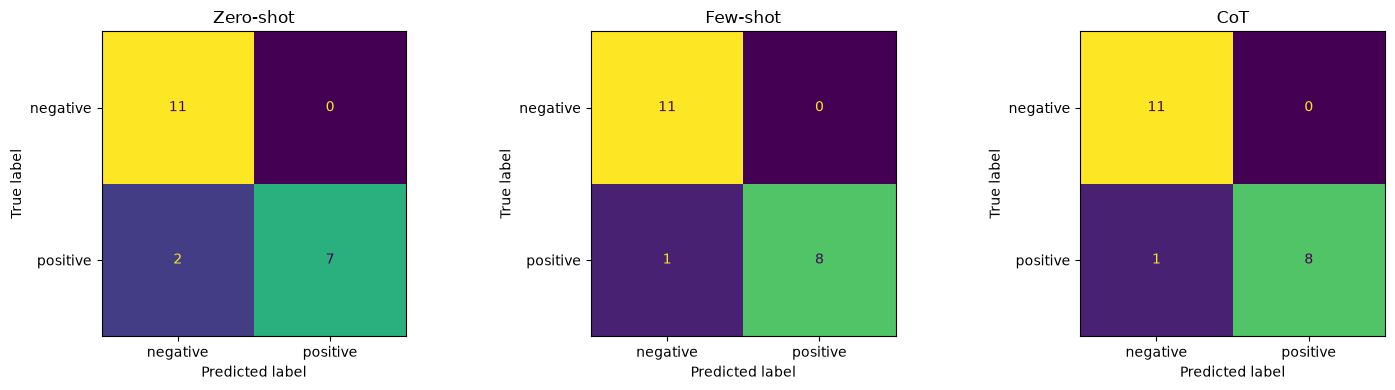

In [23]:
labels = ["negative", "positive"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, yt, yp) in zip(axes, [("Zero-shot", yt_zero, yp_zero),
                                      ("Few-shot", yt_few, yp_few),
                                      ("CoT", yt_cot, yp_cot)]):
    ConfusionMatrixDisplay(confusion_matrix(yt, yp, labels=labels), display_labels=labels).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Il ne s'agit que **d'un seul** choix d'exemples. On répète l'évaluation 10 fois avec des exemples différents pour mesurer la variabilité du micro-F1 (few-shot et CoT).

In [25]:
num_eval_runs = 10    # PDF : 10 runs. Mets 5 si l'API gratuite est trop lente / limitée
few_shot_performance, cot_few_shot_performance = [], []

for _ in tqdm(range(num_eval_runs)):
    # For each run create a new sample of examples
    examples = create_examples(examples_df)

    # Few-shot
    few_shot_prompt = create_prompt(few_shot_system_message, examples, user_message_template)
    few_shot_micro_f1 = evaluate_prompt(few_shot_prompt, gold_examples, user_message_template, llm)
    few_shot_performance.append(few_shot_micro_f1)

    # CoT (même exemples, message système différent)
    cot_few_shot_prompt = create_prompt(cot_system_message, examples, user_message_template)
    cot_micro_f1 = evaluate_prompt(cot_few_shot_prompt, gold_examples, user_message_template, llm)
    cot_few_shot_performance.append(cot_micro_f1)

100%|██████████| 10/10 [1:06:01<00:00, 396.16s/it]


                    mean    std  min   max
few_shot           0.940  0.021  0.9  0.95
cot_few_shot       0.935  0.024  0.9  0.95
zero_shot (1 run)  0.900    NaN  0.9  0.90


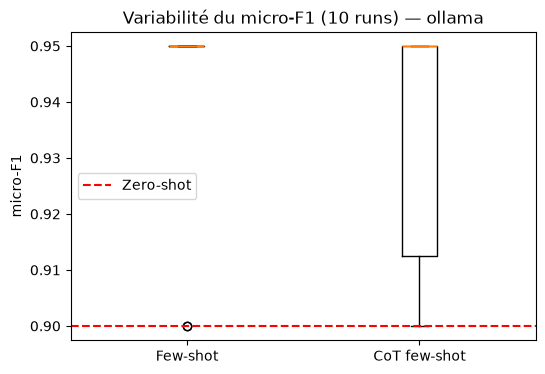

In [26]:
results = pd.DataFrame({"few_shot": few_shot_performance, "cot_few_shot": cot_few_shot_performance})
results.to_csv("results_micro_f1.csv", index=False)

summary = results.agg(["mean", "std", "min", "max"]).T
summary.loc["zero_shot (1 run)"] = [zero_f1, np.nan, zero_f1, zero_f1]
print(summary.round(3))

plt.figure(figsize=(6, 4))
plt.boxplot([results.few_shot, results.cot_few_shot], tick_labels=["Few-shot", "CoT few-shot"])
plt.axhline(zero_f1, color="r", linestyle="--", label="Zero-shot")
plt.ylabel("micro-F1")
plt.title(f"Variabilité du micro-F1 ({num_eval_runs} runs) — {PROVIDER}")
plt.legend()
plt.show()